> **Notebook obsolète.** Il utilise un découpage aléatoire 80 / 20, et la sélection des features y est faite avant le découpage. Les scores obtenus ici sont donc optimistes. Ce découpage a été abandonné au profit de celui de l'énoncé (2000 premiers cycles / 205 derniers) : voir la section 3.1 de `notebook_projet.ipynb`.

## **Prédiction avec la regression logistique sur le jeu de données**

Objectif : tester la **régression logistique** sur les 4 jeux de features préparés dans `data/processed/`, puis comparer les résultats.

Chaque jeu contient déjà son découpage train (1764 cycles) et test (441 cycles).

## 1. Imports

In [1]:
# Import des librairies 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)

# Fonction du projet qui lit x_train, x_test, y_train, y_test dans data/processed/<nom>/
from src.utils import load_processed

## 2. Fonction commune

Les 4 jeux suivent exactement les mêmes étapes, on les écrit donc une seule fois dans une fonction :

1. charger les 4 variables,
2. standardiser puis entraîner la régression logistique sur le train,
3. prédire sur le test,
4. afficher les scores et la matrice de confusion.

La standardisation met chaque colonne à moyenne 0 et écart type 1. Sans elle, les colonnes aux grandes valeurs écrasent les autres et la régression logistique apprend mal. Le `StandardScaler` est placé dans un pipeline : il apprend la moyenne et l'écart type sur le train uniquement, puis les applique au test.

In [2]:
def evaluer_reglog(nom):
    # 1. Chargement des données déjà découpées
    x_train, x_test, y_train, y_test = load_processed(nom)
    print("train :", x_train.shape, "  test :", x_test.shape)

    # 2. Standardisation puis régression logistique, enchaînées dans un pipeline
    modele = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    modele.fit(x_train, y_train)

    # 3. Prédictions sur le test : la classe (0 ou 1) et la probabilité d'être 1
    y_pred = modele.predict(x_test)
    y_proba = modele.predict_proba(x_test)[:, 1]

    # 4. Scores détaillés par classe
    print(classification_report(y_test, y_pred))

    # Matrice de confusion : lignes = vraie classe, colonnes = classe prédite
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
    plt.title(f"Régression logistique : {nom}")
    plt.show()

    # On renvoie les scores pour le tableau de comparaison final
    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "rappel": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "auc": roc_auc_score(y_test, y_proba),
    }

## 3. Jeu histogramme : Histogrammes

Chaque cycle est résumé par la part des mesures tombée dans chaque intervalle de valeurs (notebook `exploration_histogramme.ipynb`). 14 features.

train : (1764, 14)   test : (441, 14)
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       216
           1       0.99      0.99      0.99       225

    accuracy                           0.99       441
   macro avg       0.99      0.99      0.99       441
weighted avg       0.99      0.99      0.99       441



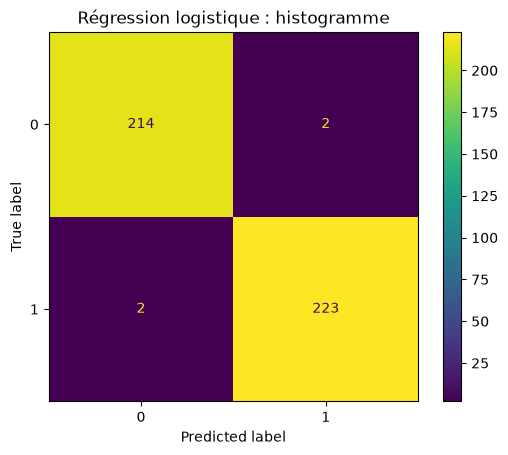

In [3]:
res_histogramme = evaluer_reglog("histogramme")

## 4. Jeu stats : Statistiques

Chaque cycle est résumé par des statistiques : moyenne, écart type, quartiles, etc. (notebook `exploration.ipynb`).

train : (1764, 7)   test : (441, 7)
              precision    recall  f1-score   support

           0       0.74      0.64      0.69       216
           1       0.69      0.78      0.73       225

    accuracy                           0.71       441
   macro avg       0.71      0.71      0.71       441
weighted avg       0.71      0.71      0.71       441



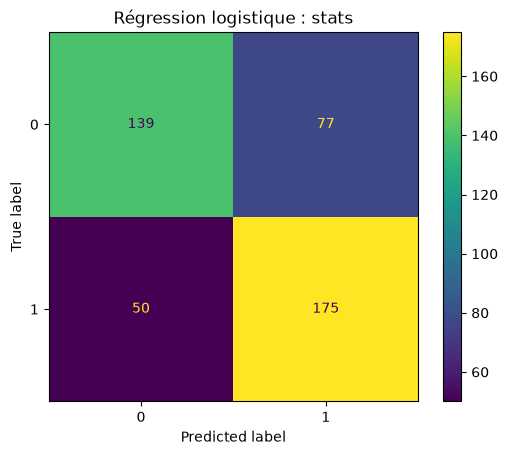

In [4]:
res_stats = evaluer_reglog("stats")

## 5. Jeu stats_spectre : Statistiques et fréquences

Mêmes statistiques, plus des valeurs tirées de la transformée de Fourier (notebook `exploration_frequence.ipynb`).

train : (1764, 9)   test : (441, 9)
              precision    recall  f1-score   support

           0       0.96      0.93      0.94       216
           1       0.93      0.96      0.95       225

    accuracy                           0.94       441
   macro avg       0.94      0.94      0.94       441
weighted avg       0.94      0.94      0.94       441



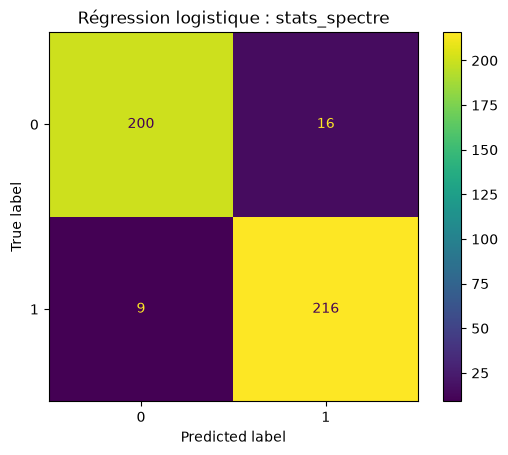

In [5]:
res_stats_spectre = evaluer_reglog("stats_spectre")

## 6. Jeu spectre : Fréquences seules

Seulement 3 features fréquentielles. Aucun notebook actuel ne produit ce jeu, il vient d'une ancienne version de `exploration_frequence.ipynb`.

train : (1764, 3)   test : (441, 3)
              precision    recall  f1-score   support

           0       0.84      0.79      0.81       216
           1       0.81      0.85      0.83       225

    accuracy                           0.82       441
   macro avg       0.82      0.82      0.82       441
weighted avg       0.82      0.82      0.82       441



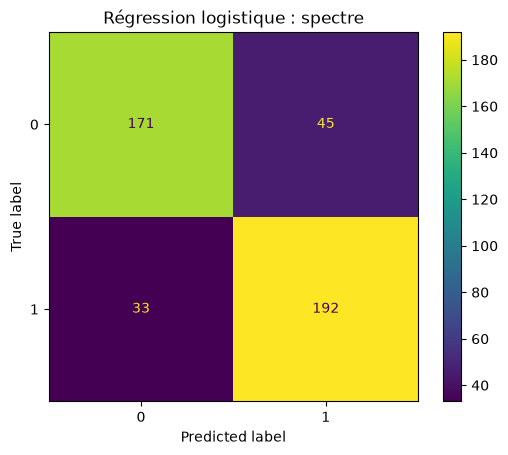

In [6]:
res_spectre = evaluer_reglog("spectre")

## 7. Comparaison des 4 jeux

Un tableau avec une ligne par jeu de features, trié du meilleur au moins bon F1.

In [7]:
resultats = pd.DataFrame({
    "histogramme": res_histogramme,
    "stats": res_stats,
    "stats_spectre": res_stats_spectre,
    "spectre": res_spectre,
}).T

resultats.sort_values("f1", ascending=False).round(3)

,accuracy,precision,rappel,f1,auc
histogramme,0.991,0.991,0.991,0.991,0.998
stats_spectre,0.943,0.931,0.960,0.945,0.979
spectre,0.823,0.810,0.853,0.831,0.916
stats,0.712,0.694,0.778,0.734,0.777


On constate qu'avec la régression logistique, les histogrammes sont nettement le meilleur jeu de features.